In [128]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [129]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:3]

['emma', 'olivia', 'ava']

In [130]:
len(words)

32035

In [131]:
# build the vocabulary of character mappings to/from integers 
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [132]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size # This used to take the starting value '.' inside the block
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(99)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

# Splitting the dataset into (Training, Validate, Test)
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

# training split, dev/validation split, test split
# 80%, 10%, 10%

torch.Size([182438, 3]) torch.Size([182438])
torch.Size([22878, 3]) torch.Size([22878])
torch.Size([22841, 3]) torch.Size([22841])


In [133]:
Xtr.shape, Xtr.dtype, Ytr.shape, Ytr.dtype

(torch.Size([182438, 3]), torch.int64, torch.Size([182438]), torch.int64)

In [134]:
C = torch.randn(27,5)
'''NOTE: now to see the vector made in C for our 27 characters we can just use 'C[5]' Which will give us the 5th row from the matrix
   that is the simple way what we can also do is we can use 'F.one_hot()' to convert this into a matrix of dim 27
   where only the 5th element is toggled to 1 other are 0 and we can do matrix multiplication with 'C' this will also create the same result
   following the rersearch paper we stick to lookup.'''

"NOTE: now to see the vector made in C for our 27 characters we can just use 'C[5]' Which will give us the 5th row from the matrix\n   that is the simple way what we can also do is we can use 'F.one_hot()' to convert this into a matrix of dim 27\n   where only the 5th element is toggled to 1 other are 0 and we can do matrix multiplication with 'C' this will also create the same result\n   following the rersearch paper we stick to lookup."

In [135]:
C

tensor([[-0.2203,  1.1271,  2.2417,  0.8731, -0.6372],
        [-0.0993, -0.7893, -0.4828,  1.2135,  1.4360],
        [-0.0229, -1.4088, -1.4601,  0.1327,  0.9883],
        [ 1.3694,  0.3874,  1.3159,  0.2668,  1.5507],
        [ 1.5966,  0.4217, -1.0461, -0.5943, -2.0820],
        [ 1.0799, -1.1046, -2.0930,  1.4985, -0.1930],
        [-0.8522, -0.2316,  0.0106, -0.7477, -0.3727],
        [-0.5306,  0.4996, -0.5801, -0.0234, -0.6351],
        [-0.4551,  0.9668,  0.7393,  0.0313,  0.8742],
        [ 0.8133, -0.7005, -0.6463,  0.3563, -0.4034],
        [-0.6673,  0.3287,  0.9363, -0.3655,  0.2532],
        [ 0.0216, -1.5828, -0.5056, -0.4284,  0.9540],
        [-1.0282,  0.8550,  1.4366,  1.1376,  0.0934],
        [ 1.0546, -1.9065, -0.2508, -0.1939, -0.8379],
        [ 0.3654, -0.9958, -0.3852, -0.3332,  0.4494],
        [ 0.4231,  0.9894,  0.9233,  1.8378,  0.7561],
        [ 0.7731,  0.7027, -0.2730,  0.1437,  0.3819],
        [ 1.2952,  1.5498,  0.6683, -0.1892,  0.7335],
        [ 

In [136]:
C[5] # Following the paper using this 

tensor([ 1.0799, -1.1046, -2.0930,  1.4985, -0.1930])

In [137]:
F.one_hot(torch.tensor(5), num_classes=27).float() @ C

tensor([ 1.0799, -1.1046, -2.0930,  1.4985, -0.1930])

In [138]:
# indexing
C[Xtr] # [32, 3, 5]

tensor([[[-0.2203,  1.1271,  2.2417,  0.8731, -0.6372],
         [-0.2203,  1.1271,  2.2417,  0.8731, -0.6372],
         [-0.2203,  1.1271,  2.2417,  0.8731, -0.6372]],

        [[-0.2203,  1.1271,  2.2417,  0.8731, -0.6372],
         [-0.2203,  1.1271,  2.2417,  0.8731, -0.6372],
         [-0.5306,  0.4996, -0.5801, -0.0234, -0.6351]],

        [[-0.2203,  1.1271,  2.2417,  0.8731, -0.6372],
         [-0.5306,  0.4996, -0.5801, -0.0234, -0.6351],
         [ 0.8133, -0.7005, -0.6463,  0.3563, -0.4034]],

        ...,

        [[ 1.5966,  0.4217, -1.0461, -0.5943, -2.0820],
         [-0.0993, -0.7893, -0.4828,  1.2135,  1.4360],
         [-0.1511,  0.7448,  0.5867,  0.7932,  0.0462]],

        [[-0.0993, -0.7893, -0.4828,  1.2135,  1.4360],
         [-0.1511,  0.7448,  0.5867,  0.7932,  0.0462],
         [-0.0993, -0.7893, -0.4828,  1.2135,  1.4360]],

        [[-0.1511,  0.7448,  0.5867,  0.7932,  0.0462],
         [-0.0993, -0.7893, -0.4828,  1.2135,  1.4360],
         [ 0.3654, -0.99

In [139]:
C[Xtr][13,2]

tensor([-0.0993, -0.7893, -0.4828,  1.2135,  1.4360])

In [140]:
Xtr[13,2]

tensor(1)

In [141]:
C[1]

tensor([-0.0993, -0.7893, -0.4828,  1.2135,  1.4360])

In [142]:
# Layer 1
emb = C[Xtr]
emb.shape

torch.Size([182438, 3, 5])

In [143]:
# Hidden Layer
W1 = torch.randn((15, 150))
b1 = torch.randn(150)

In [144]:
h = torch.tanh(emb.view(-1, 15) @ W1 + b1)

In [145]:
h

tensor([[ 0.9998, -0.9162, -0.9999,  ...,  0.9736, -0.6934, -0.9978],
        [ 1.0000, -0.9452, -0.2300,  ..., -0.7617, -0.9232, -0.8728],
        [ 0.9998, -0.9862, -0.2043,  ..., -0.9992,  0.8526, -0.2647],
        ...,
        [-0.9999,  0.9984, -0.9999,  ...,  1.0000, -0.9991,  0.9900],
        [-0.9965, -0.9977,  0.9997,  ...,  0.9967, -0.9665, -0.9997],
        [ 0.7706,  0.2467,  0.9798,  ..., -0.3218,  0.5565,  0.9853]])

In [146]:
h.shape

torch.Size([182438, 150])

In [147]:
# Final Layer
W2 = torch.randn((150, 27))
b2 = torch.randn((27))

In [148]:
logits = h @ W2 + b2

In [149]:
logits.shape 

torch.Size([182438, 27])

In [150]:
counts = logits.exp()

In [151]:
prob = counts / counts.sum(1, keepdims=True)

In [152]:
prob.shape

torch.Size([182438, 27])

In [153]:
# loss = -prob[torch.arange(182566), Ytr].log().mean() # negative log_likelihood
# loss

In [154]:
# ------------ now made respectable :) ---------------

In [155]:
Xtr.shape, Ytr.shape # dataset

(torch.Size([182438, 3]), torch.Size([182438]))

In [156]:
g = torch.Generator().manual_seed(45127676)

C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)

parameters = [C, W1, b1, W2, b2]

In [157]:
sum(p.nelement() for p in parameters) # number of parameters in total

11897

In [158]:
for p in parameters:
  p.requires_grad = True

In [159]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [160]:
lri = []
lossi = []
stepi = []

In [161]:
for i in range(200000):
  
  # Minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (32,))
  
  # Forward pass
  emb = C[Xtr[ix]] # (32, 3, 10)
  h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 200)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  
  # Backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # Update (learning rate decay)
  #lr = lrs[i]
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # Track stats
  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

#print(loss.item())

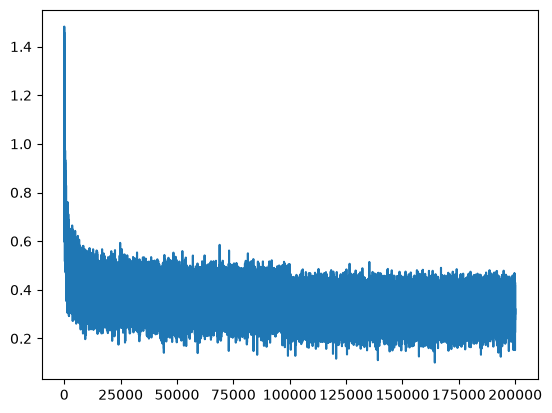

In [162]:
plt.plot(stepi, lossi)

In [163]:
print(loss.item()) # Got very far from the biagram model in terms of loss value

1.9049301147460938


In [164]:
# Networks seen values
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1218, grad_fn=<NllLossBackward0>)

In [165]:
# Networks not seen values 
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1736, grad_fn=<NllLossBackward0>)

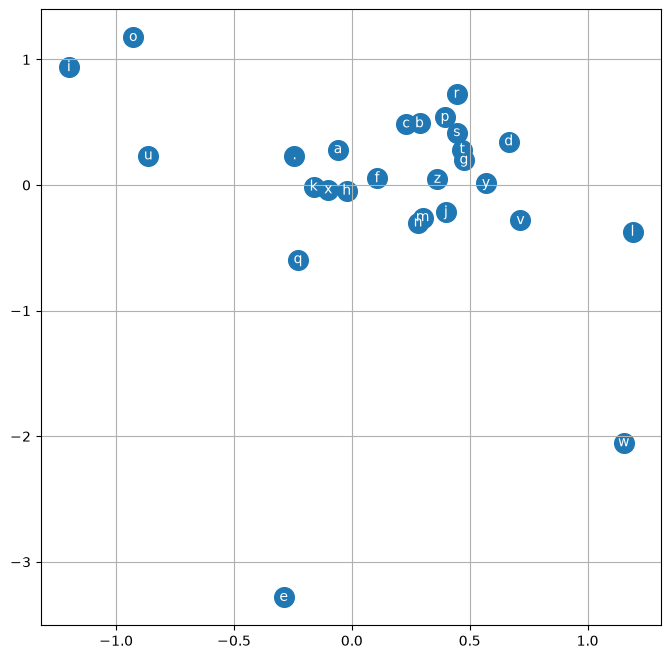

In [166]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [167]:
context = [0] * block_size
C[torch.tensor([context])].shape

torch.Size([1, 3, 10])

In [173]:
# sample from the model

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

kahlianna.
vious.
jokshengaelicy.
sumerichien.
all.
onmete.
paid.
karsenri.
harin.
rosetteonne.
aslyndidhahzin.
maleen.
bairiiamshaya.
lundhe.
suhia.
arbethelsonell.
lymaramelorarylyn.
miquetdettontlie.
sha.
fabrevila.
